# ARTI 403 — Image Processing
## Lab 1 — Basics of Programming with Python

**College of Computer Science and Information Technology — Department of Computer Engineering**  
**Imam Abdulrahman Bin Faisal University — 2026 / 2027**

| | |
|---|---|
| **Session topic** | Basics of programming with Python |
| **Session No.** | 1 |
| **Duration** | 100 minutes |
| **Student name** | *&lt;write your name here&gt;* |
| **Student ID** | *&lt;write your ID here&gt;* |

### Session outcome
**Outcome #1:** Explain how digital images are represented and manipulated in a computer.

### Contents
1. [Environment setup (Steps 1–4)](#setup)
2. [Task 1 — Exercise with Spyder: Python & NumPy practice](#task1)
3. [Task 2 — Loading and visualizing images](#task2)
4. [Task 3 — Image storing](#task3)
5. [Task 4 — Display the image as an array](#task4)
6. [Assessment — NumPy operations on the image array](#assessment)
7. [Conclusion](#conclusion)

<a id="setup"></a>
## 1. Environment setup (Steps 1–4)

**Step 1 — Install Anaconda.** Anaconda was downloaded from <https://www.anaconda.com/> and installed. It ships with both target IDEs of this course, **Jupyter** and **Spyder**.

**Step 2 — Start Jupyter / Spyder.** Both can be launched from Anaconda Navigator, or directly from the Start menu (`Jupyter Notebook`, `Spyder`) without opening Navigator, which is faster.

**Step 3 — Install the libraries.** The libraries needed for this course are **SciPy, OpenCV, scikit-image, Pillow and Matplotlib**:

```bash
conda install -c conda-forge scipy opencv scikit-image pillow matplotlib
# or, with pip:
pip install scipy opencv-python scikit-image pillow matplotlib
```

**Step 4 — Install NumPy** (<https://pypi.org/project/numpy/>):

```bash
conda install numpy        # or:  pip install numpy
```

The cell below verifies that every required package is importable and prints the installed versions.

In [1]:
import sys
import numpy as np
import cv2
import PIL
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

print("Python     :", sys.version.split()[0])
print("NumPy      :", np.__version__)
print("OpenCV     :", cv2.__version__)
print("Pillow     :", PIL.__version__)
print("Matplotlib :", matplotlib.__version__)

Python     : 3.14.5
NumPy      : 2.5.3
OpenCV     : 5.0.0
Pillow     : 12.3.0
Matplotlib : 3.11.1


<a id="task1"></a>
## 2. Task 1 — Exercise with Spyder

> *"Exercise the two cheat sheets for Python practice in the resources section."*  
> (Resources: **Python Basics cheat sheet**, **NumPy cheat sheet**.)

Both cheat sheets are worked through below: first the plain-Python part, then the NumPy part. These are exactly the building blocks needed to manipulate images, because **a digital image is nothing more than a NumPy array of numbers**.

### 2.1 Python basics cheat sheet

In [2]:
# ---- Variables and data types -------------------------------------------------
width      = 256          # int
height     = 256          # int
scale      = 0.5          # float
image_name = "lena"       # str
is_gray    = True         # bool

print(width, type(width))
print(scale, type(scale))
print(image_name, type(image_name))
print(is_gray, type(is_gray))

# ---- Arithmetic and type conversion -------------------------------------------
print("\nnumber of pixels :", width * height)
print("half the width   :", width * scale, "->", int(width * scale))
print("integer division :", width // 3, " remainder:", width % 3)
print("power            :", 2 ** 8, "(= number of gray levels of an 8-bit image)")

256 <class 'int'>
0.5 <class 'float'>
lena <class 'str'>
True <class 'bool'>

number of pixels : 65536
half the width   : 128.0 -> 128
integer division : 85  remainder: 1
power            : 256 (= number of gray levels of an 8-bit image)


In [3]:
# ---- Strings ------------------------------------------------------------------
title = "Digital Image Processing"

print(title.upper())
print(title.lower())
print(title.replace("Digital", "ARTI 403"))
print("length      :", len(title))
print("slice [0:7] :", title[0:7])
print("split       :", title.split())
print(f"f-string    : the image '{image_name}' is {width}x{height} pixels")

DIGITAL IMAGE PROCESSING
digital image processing
ARTI 403 Image Processing
length      : 24
slice [0:7] : Digital
split       : ['Digital', 'Image', 'Processing']
f-string    : the image 'lena' is 256x256 pixels


In [4]:
# ---- Lists (ordered, mutable) -------------------------------------------------
gray_levels = [0, 32, 64, 128, 192, 255]

print("list         :", gray_levels)
print("first / last :", gray_levels[0], gray_levels[-1])
print("slice [1:4]  :", gray_levels[1:4])

gray_levels.append(200)          # add at the end
gray_levels.insert(1, 16)        # add at a given position
gray_levels.remove(200)          # remove by value
gray_levels.sort()               # sort in place
print("after edits  :", gray_levels)
print("min/max/sum  :", min(gray_levels), max(gray_levels), sum(gray_levels))

# ---- Tuples (ordered, immutable) — used by OpenCV/PIL for image sizes ---------
size = (width, height)
print("\ntuple        :", size, "-> unpacked:", *size)

list         : [0, 32, 64, 128, 192, 255]
first / last : 0 255
slice [1:4]  : [32, 64, 128]
after edits  : [0, 16, 32, 64, 128, 192, 255]
min/max/sum  : 0 255 687

tuple        : (256, 256) -> unpacked: 256 256


In [5]:
# ---- Dictionary (key -> value) ------------------------------------------------
image_info = {"name": "lena_gray_256", "format": "tif", "mode": "L", "size": size}

print("dict      :", image_info)
print("keys      :", list(image_info.keys()))
print("one value :", image_info["size"])
for k, v in image_info.items():
    print(f"   {k:8s} = {v}")

# ---- Set (unordered, unique) — the basis of the set operations of Lab 2 -------
A = {1, 2, 3, 4}
B = {3, 4, 5, 6}
print("\nA | B  (union)                :", A | B)
print("A & B  (intersection)         :", A & B)
print("A - B  (difference)           :", A - B)
print("A ^ B  (symmetric difference) :", A ^ B)

dict      : {'name': 'lena_gray_256', 'format': 'tif', 'mode': 'L', 'size': (256, 256)}
keys      : ['name', 'format', 'mode', 'size']
one value : (256, 256)
   name     = lena_gray_256
   format   = tif
   mode     = L
   size     = (256, 256)

A | B  (union)                : {1, 2, 3, 4, 5, 6}
A & B  (intersection)         : {3, 4}
A - B  (difference)           : {1, 2}
A ^ B  (symmetric difference) : {1, 2, 5, 6}


In [6]:
# ---- Conditions ---------------------------------------------------------------
pixel = 130

if pixel > 200:
    category = "bright"
elif pixel > 100:
    category = "mid-gray"
else:
    category = "dark"
print(f"a pixel of value {pixel} is {category}")

# ---- Loops --------------------------------------------------------------------
print("\nfor loop over a list:")
for g in [0, 128, 255]:
    print("   gray level", g)

print("\nfor loop with range:")
for i in range(0, 5):
    print("   row", i, end="  |")
print()

print("\nwhile loop (successive halving = pyramid of resolutions):")
n = 256
while n > 16:
    print("   resolution", n, "x", n)
    n //= 2

# ---- List comprehension (compact and fast) ------------------------------------
squares   = [i ** 2 for i in range(6)]
negatives = [255 - g for g in [0, 64, 128, 255]]      # the negative of a gray level
print("\nsquares            :", squares)
print("negative of levels :", negatives)

a pixel of value 130 is mid-gray

for loop over a list:
   gray level 0
   gray level 128
   gray level 255

for loop with range:
   row 0  |   row 1  |   row 2  |   row 3  |   row 4  |

while loop (successive halving = pyramid of resolutions):
   resolution 256 x 256
   resolution 128 x 128
   resolution 64 x 64
   resolution 32 x 32

squares            : [0, 1, 4, 9, 16, 25]
negative of levels : [255, 191, 127, 0]


In [7]:
# ---- Functions ----------------------------------------------------------------
def bits_to_levels(bits):
    # Return the number of gray levels representable with `bits` bits.
    return 2 ** bits


def image_memory(width, height, bits=8, channels=1):
    # Return the raw (uncompressed) size of an image, in bytes.
    return width * height * channels * bits // 8


for b in (1, 2, 4, 8):
    print(f"{b} bit(s) -> {bits_to_levels(b):3d} gray levels")

size_bytes = image_memory(256, 256, bits=8, channels=1)
print(f"\na 256x256 8-bit gray image needs {size_bytes} bytes = {size_bytes/1024:.0f} KB")
print(f"a 256x256 8-bit RGB  image needs {image_memory(256, 256, 8, 3)} bytes "
      f"= {image_memory(256, 256, 8, 3)/1024:.0f} KB")

1 bit(s) ->   2 gray levels
2 bit(s) ->   4 gray levels
4 bit(s) ->  16 gray levels
8 bit(s) -> 256 gray levels

a 256x256 8-bit gray image needs 65536 bytes = 64 KB
a 256x256 8-bit RGB  image needs 196608 bytes = 192 KB


### 2.2 NumPy cheat sheet

NumPy is the library that actually holds the image data: **every image loaded with OpenCV, or converted from PIL, is an `ndarray`**, so each operation below is directly an image operation.

In [8]:
import numpy as np

# ---- Creating arrays ----------------------------------------------------------
a = np.array([1, 2, 3, 4, 5])                 # from a list
b = np.zeros((3, 4), dtype=np.uint8)          # a black 3x4 image
c = np.ones((3, 4), dtype=np.uint8) * 255     # a white 3x4 image
d = np.full((2, 3), 128, dtype=np.uint8)      # a uniform mid-gray patch
e = np.arange(0, 256, 64)                     # 0, 64, 128, 192
f = np.linspace(0, 255, 5)                    # 5 evenly spaced values
g = np.eye(4, dtype=np.uint8)                 # identity matrix

print("a =", a)
print("e =", e)
print("f =", f)
print("\nb (zeros -> black) =\n", b)
print("\nc (ones*255 -> white) =\n", c)
print("\nd (uniform mid-gray) =\n", d)
print("\ng (identity) =\n", g)

a = [1 2 3 4 5]
e = [  0  64 128 192]
f = [  0.    63.75 127.5  191.25 255.  ]

b (zeros -> black) =
 [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]

c (ones*255 -> white) =
 [[255 255 255 255]
 [255 255 255 255]
 [255 255 255 255]]

d (uniform mid-gray) =
 [[128 128 128]
 [128 128 128]]

g (identity) =
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]


In [9]:
# ---- Attributes of an array ---------------------------------------------------
patch = np.array([[ 10,  20,  30,  40],
                  [ 50,  60,  70,  80],
                  [ 90, 100, 110, 120]], dtype=np.uint8)

print("array =\n", patch)
print("\nshape    :", patch.shape,    "  (rows, columns)")
print("size     :", patch.size,     "  (total number of elements)")
print("ndim     :", patch.ndim,     "  (number of dimensions)")
print("dtype    :", patch.dtype,    "  (data type of one pixel)")
print("itemsize :", patch.itemsize, " byte(s) per element")
print("nbytes   :", patch.nbytes,   " bytes in total")

array =
 [[ 10  20  30  40]
 [ 50  60  70  80]
 [ 90 100 110 120]]

shape    : (3, 4)   (rows, columns)
size     : 12   (total number of elements)
ndim     : 2   (number of dimensions)
dtype    : uint8   (data type of one pixel)
itemsize : 1  byte(s) per element
nbytes   : 12  bytes in total


In [10]:
# ---- Indexing and slicing (this is how a region of interest is cropped) -------
print("patch =\n", patch)
print("\npatch[0, 0]     :", patch[0, 0],   "  -> single pixel (row 0, column 0)")
print("patch[2, 3]     :", patch[2, 3],   "  -> last pixel")
print("patch[-1, -1]   :", patch[-1, -1], "  -> the same, with negative indexing")
print("\npatch[0]        :", patch[0],    " -> first row")
print("patch[:, 1]     :", patch[:, 1], " -> second column")
print("\npatch[0:2, 1:3] =\n", patch[0:2, 1:3], "\n   -> a 2x2 sub-image (crop)")
print("\npatch[::-1] =\n", patch[::-1], "\n   -> rows reversed (vertical flip)")
print("\npatch[:, ::-1] =\n", patch[:, ::-1], "\n   -> columns reversed (horizontal flip)")

patch =
 [[ 10  20  30  40]
 [ 50  60  70  80]
 [ 90 100 110 120]]

patch[0, 0]     : 10   -> single pixel (row 0, column 0)
patch[2, 3]     : 120   -> last pixel
patch[-1, -1]   : 120   -> the same, with negative indexing

patch[0]        : [10 20 30 40]  -> first row
patch[:, 1]     : [ 20  60 100]  -> second column

patch[0:2, 1:3] =
 [[20 30]
 [60 70]] 
   -> a 2x2 sub-image (crop)

patch[::-1] =
 [[ 90 100 110 120]
 [ 50  60  70  80]
 [ 10  20  30  40]] 
   -> rows reversed (vertical flip)

patch[:, ::-1] =
 [[ 40  30  20  10]
 [ 80  70  60  50]
 [120 110 100  90]] 
   -> columns reversed (horizontal flip)


In [11]:
# ---- Element-wise arithmetic (broadcasting) -----------------------------------
print("patch + 10 =\n", patch + 10, "     <- brightening")
print("\npatch // 2 =\n", patch // 2, "     <- darkening")
print("\n255 - patch =\n", 255 - patch, "    <- photographic negative")
print("\npatch * 2 =\n", patch * 2, "      <- contrast stretching")

# ---- Comparison / boolean masking ---------------------------------------------
mask = patch > 60
print("\nmask (patch > 60) =\n", mask)
print("\nnumber of pixels above 60 :", mask.sum())

thresholded = np.where(patch > 60, 255, 0).astype(np.uint8)
print("\nthresholded =\n", thresholded, "   <- a binary image")

patch + 10 =
 [[ 20  30  40  50]
 [ 60  70  80  90]
 [100 110 120 130]]      <- brightening

patch // 2 =
 [[ 5 10 15 20]
 [25 30 35 40]
 [45 50 55 60]]      <- darkening

255 - patch =
 [[245 235 225 215]
 [205 195 185 175]
 [165 155 145 135]]     <- photographic negative

patch * 2 =
 [[ 20  40  60  80]
 [100 120 140 160]
 [180 200 220 240]]       <- contrast stretching

mask (patch > 60) =
 [[False False False False]
 [False False  True  True]
 [ True  True  True  True]]

number of pixels above 60 : 6

thresholded =
 [[  0   0   0   0]
 [  0   0 255 255]
 [255 255 255 255]]    <- a binary image


In [12]:
# ---- Statistics (the numbers behind a histogram) ------------------------------
print("min    :", patch.min())
print("max    :", patch.max())
print("mean   :", patch.mean())
print("std    :", patch.std())
print("sum    :", patch.sum())
print("median :", np.median(patch))
print("\nper-column mean (axis=0):", patch.mean(axis=0))
print("per-row    mean (axis=1):", patch.mean(axis=1))

# ---- Reshaping and joining -----------------------------------------------------
print("\nflatten (1-D) :", patch.flatten())
print("\nreshape(4, 3) =\n", patch.reshape(4, 3))
print("\ntranspose (.T) =\n", patch.T)
print("\nvertical stack =\n", np.vstack([patch, patch]))
print("\nhorizontal stack =\n", np.hstack([patch, patch]))

min    : 10
max    : 120
mean   : 65.0
std    : 34.52052529534663
sum    : 780
median : 65.0

per-column mean (axis=0): [50. 60. 70. 80.]
per-row    mean (axis=1): [ 25.  65. 105.]

flatten (1-D) : [ 10  20  30  40  50  60  70  80  90 100 110 120]

reshape(4, 3) =
 [[ 10  20  30]
 [ 40  50  60]
 [ 70  80  90]
 [100 110 120]]

transpose (.T) =
 [[ 10  50  90]
 [ 20  60 100]
 [ 30  70 110]
 [ 40  80 120]]

vertical stack =
 [[ 10  20  30  40]
 [ 50  60  70  80]
 [ 90 100 110 120]
 [ 10  20  30  40]
 [ 50  60  70  80]
 [ 90 100 110 120]]

horizontal stack =
 [[ 10  20  30  40  10  20  30  40]
 [ 50  60  70  80  50  60  70  80]
 [ 90 100 110 120  90 100 110 120]]


In [13]:
# ---- IMPORTANT: the uint8 data type wraps around -------------------------------
# An 8-bit pixel can only hold 0..255. Going outside that range wraps around
# (modulo 256), which is the classic pitfall of image arithmetic (see Lab 2).
u = np.array([250, 251, 252], dtype=np.uint8)
print("uint8 [250 251 252] + 10 =", (u + 10), "  <- WRAPPED AROUND, not 260, 261, 262!")

# Two safe ways of doing the same addition:
print("np.clip on int16         =", np.clip(u.astype(np.int16) + 10, 0, 255).astype(np.uint8))

# cv2.add() saturates instead of wrapping. Note the reshape to (1, 3): OpenCV
# would read a flat 3-element array as a single colour Scalar, not as 3 pixels.
print("cv2.add (saturating)     =", cv2.add(u.reshape(1, 3), np.uint8([[10, 10, 10]])).ravel())

uint8 [250 251 252] + 10 = [4 5 6]   <- WRAPPED AROUND, not 260, 261, 262!
np.clip on int16         = [255 255 255]
cv2.add (saturating)     = [255 255 255]


<a id="task2"></a>
## 3. Task 2 — Loading and visualizing images

### (a) Loading / reading an image using OpenCV

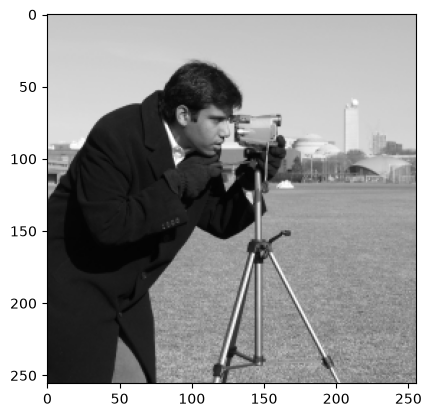

In [14]:
import cv2
img = cv2.imread('../images/cameraman.tif')     # Load the image data into a NumPy array

import matplotlib.pyplot as plt
plt.imshow(img)
plt.show()

**Observation.** Two things must be noticed about the figure above:

1. `cv2.imread()` called **without a flag always returns a 3-channel BGR array**, even for a gray-scale file — the gray value is simply replicated over the three channels.
2. Matplotlib expects **RGB**, so an image read by OpenCV and passed directly to `plt.imshow()` has its red and blue channels swapped. Here R = G = B, so no colour shift is visible, but the image is still being handled as a true-colour image instead of a gray-scale one.

The two correct ways of loading and displaying it are shown next.

shape of img (default read) : (256, 256, 3) -> 3 channels (BGR)
shape of img_gray           : (256, 256) -> 1 channel


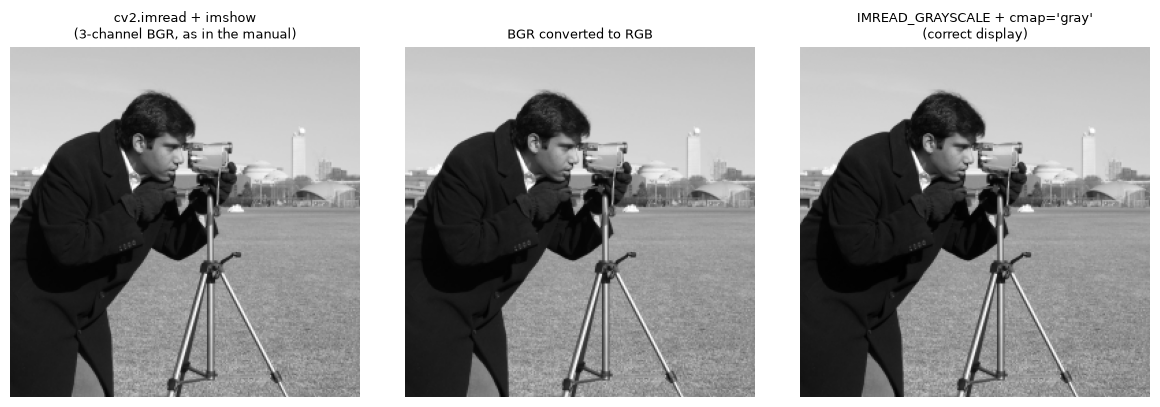

In [15]:
print("shape of img (default read) :", img.shape, "-> 3 channels (BGR)")

# The right way for a gray-scale image: read it as a single channel
img_gray = cv2.imread('../images/cameraman.tif', cv2.IMREAD_GRAYSCALE)
print("shape of img_gray           :", img_gray.shape, "-> 1 channel")

# And the right way for a colour image: convert BGR -> RGB before plotting
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title('cv2.imread + imshow\n(3-channel BGR, as in the manual)', fontsize=9)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_rgb)
plt.title('BGR converted to RGB', fontsize=9)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_gray, cmap='gray')
plt.title("IMREAD_GRAYSCALE + cmap='gray'\n(correct display)", fontsize=9)
plt.axis('off')

plt.tight_layout()
plt.show()

### (b) Loading / reading an image using PIL

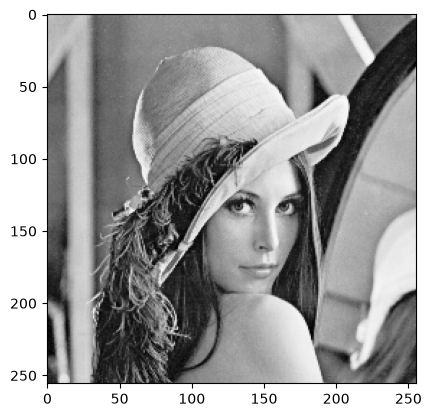

In [16]:
from PIL import Image
img2 = Image.open('../images/lena_gray_256.tif')   # load the image into a PIL Image object

import matplotlib.pyplot as plt
import matplotlib.cm as cm
plt.imshow(img2, cmap = cm.Greys_r)
plt.show()

In [17]:
# A PIL image is an object, not an array: it carries its own metadata
print("type   :", type(img2))
print("format :", img2.format, "  (file format on disk)")
print("mode   :", img2.mode,   "  ('L' = 8-bit gray, 'RGB' = 8-bit colour, '1' = binary)")
print("size   :", img2.size,   "  (width, height)  <-- PIL uses (W, H)")
print("         NumPy / OpenCV instead use (H, W) =", np.array(img2).shape)

type   : <class 'PIL.TiffImagePlugin.TiffImageFile'>
format : TIFF   (file format on disk)
mode   : L   ('L' = 8-bit gray, 'RGB' = 8-bit colour, '1' = binary)
size   : (256, 256)   (width, height)  <-- PIL uses (W, H)
         NumPy / OpenCV instead use (H, W) = (256, 256)


<a id="task3"></a>
## 4. Task 3 — Image storing

### (a) Saving an image to disk using OpenCV

In [18]:
import os
os.makedirs('output', exist_ok=True)

cv2.imwrite('output/new_image.jpg', img)
print("saved with OpenCV :", os.path.exists('output/new_image.jpg'),
      "-", os.path.getsize('output/new_image.jpg'), "bytes")

saved with OpenCV : True - 23485 bytes


### (b) Saving an image to disk using PIL

In [19]:
img2.save('output/new_image2.jpg')
print("saved with PIL    :", os.path.exists('output/new_image2.jpg'),
      "-", os.path.getsize('output/new_image2.jpg'), "bytes")

# Both libraries choose the encoder from the file extension:
cv2.imwrite('output/cameraman_copy.png', img_gray)      # lossless PNG
img2.save('output/lena_copy.bmp')                       # uncompressed BMP

print()
for fname in sorted(os.listdir('output')):
    print(f"   {fname:22s} {os.path.getsize('output/' + fname):7d} bytes")

saved with PIL    : True - 11433 bytes

   cameraman_copy.png       37379 bytes
   lena_copy.bmp            66614 bytes
   new_image.jpg            23485 bytes
   new_image2.jpg           11433 bytes


In [20]:
# Why the sizes differ: JPEG is lossy, while PNG / BMP / TIFF are lossless.
raw = 256 * 256 * 1
print(f"raw uncompressed 256x256 gray image : {raw} bytes")
print(f"lena saved as BMP  (lossless)       : {os.path.getsize('output/lena_copy.bmp')} bytes")
print(f"lena saved as JPEG (lossy)          : {os.path.getsize('output/new_image2.jpg')} bytes")

# Re-loading the JPEG shows that the pixel values have actually been changed:
lena_orig = np.array(img2, dtype=np.int16)
lena_jpeg = np.array(Image.open('output/new_image2.jpg'), dtype=np.int16)
print(f"\nmax difference introduced by JPEG   : {np.abs(lena_orig - lena_jpeg).max()} gray levels")
print(f"mean absolute difference            : {np.abs(lena_orig - lena_jpeg).mean():.3f}")

raw uncompressed 256x256 gray image : 65536 bytes
lena saved as BMP  (lossless)       : 66614 bytes
lena saved as JPEG (lossy)          : 11433 bytes

max difference introduced by JPEG   : 37 gray levels
mean absolute difference            : 3.345


<a id="task4"></a>
## 5. Task 4 — Display the image as an array

In [21]:
print(img.shape)    # Note: img loaded using OpenCV is a NumPy array
print(img)

(256, 256, 3)
[[[200 200 200]
  [200 200 200]
  [200 200 200]
  ...
  [190 190 190]
  [190 190 190]
  [190 190 190]]

 [[200 200 200]
  [199 199 199]
  [200 200 200]
  ...
  [190 190 190]
  [190 190 190]
  [190 190 190]]

 [[200 200 200]
  [200 200 200]
  [199 199 199]
  ...
  [191 191 191]
  [191 191 191]
  [191 191 191]]

 ...

 [[ 25  25  25]
  [ 25  25  25]
  [ 24  24  24]
  ...
  [138 138 138]
  [146 146 146]
  [115 115 115]]

 [[ 25  25  25]
  [ 25  25  25]
  [ 26  26  26]
  ...
  [141 141 141]
  [160 160 160]
  [146 146 146]]

 [[ 25  25  25]
  [ 26  26  26]
  [ 25  25  25]
  ...
  [143 143 143]
  [148 148 148]
  [153 153 153]]]


In [22]:
import numpy as np

# Convert the image to a NumPy array
img_array = np.array(img2)

# Print the array
print(img_array.shape)
print(img_array)

(256, 256)
[[162 162 162 ... 168 171 155]
 [162 162 162 ... 168 171 155]
 [162 162 162 ... 168 171 155]
 ...
 [ 48  57  54 ...  75  97  88]
 [ 46  50  52 ...  89 100  98]
 [ 44  55  54 ...  97 100 105]]


A 10x10 block of Lena, as numbers:

[[ 77  82  74  71  64  85  83  77  63  57]
 [ 77  84  64  77  87  87  66  66  43  41]
 [ 76  60  66  99  73  65  47  45  42  65]
 [ 63  70  98  94  62  44  39  41  44  67]
 [ 83  90  96  81  54  49  50  42  47  82]
 [ 77 105 101  66  55  52  54  42  55  81]
 [ 66  91  90  74  56  47  45  45  67  66]
 [ 61 100  83  68  77  65  62  51  71  59]
 [ 53  73  81  85  72  96  61  37  75  63]
 [ 51  73  89  62  71  84  59  47  73  66]]


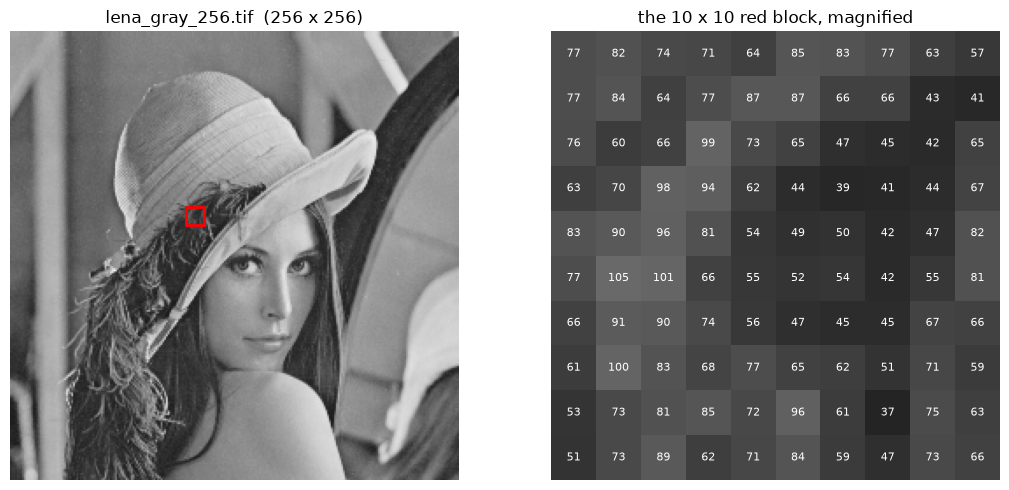

In [23]:
# A readable view of what an image really is: a small block of numbers, and the
# very same block displayed as pixels.
block = img_array[100:110, 100:110]

print("A 10x10 block of Lena, as numbers:\n")
print(block)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(img_array, cmap='gray', vmin=0, vmax=255)
ax[0].add_patch(plt.Rectangle((100, 100), 10, 10, edgecolor='red', facecolor='none', lw=2))
ax[0].set_title('lena_gray_256.tif  (256 x 256)')
ax[0].axis('off')

ax[1].imshow(block, cmap='gray', vmin=0, vmax=255)
ax[1].set_title('the 10 x 10 red block, magnified')
ax[1].axis('off')
for i in range(10):
    for j in range(10):
        # write the value in black over a light pixel and in white over a dark one
        ax[1].text(j, i, block[i, j], ha='center', va='center', fontsize=8,
                   color=('black' if block[i, j] > 127 else 'white'))

plt.tight_layout()
plt.show()

<a id="assessment"></a>
## 6. Assessment — Operations on the array using NumPy

> *"The student will be asked to perform different operations on the array using the NumPy library."*

Every operation below is a pure NumPy operation applied to the 256 × 256 Lena array.

In [24]:
A = np.array(Image.open('../images/lena_gray_256.tif'))
print("working array :", A.shape, A.dtype)

# ---- 1. Basic statistics of the image ------------------------------------------
print("\n--- 1. Statistics -------------------------------")
print(f"minimum gray level : {A.min()}")
print(f"maximum gray level : {A.max()}")
print(f"mean  (brightness) : {A.mean():.2f}")
print(f"std   (contrast)   : {A.std():.2f}")
print(f"median             : {np.median(A)}")
print(f"number of pixels   : {A.size}")
print(f"distinct levels    : {len(np.unique(A))} out of 256")

working array : (256, 256) uint8

--- 1. Statistics -------------------------------
minimum gray level : 26
maximum gray level : 242
mean  (brightness) : 124.01
std   (contrast)   : 47.84
median             : 129.0
number of pixels   : 65536
distinct levels    : 210 out of 256


--- 2. Slicing ----------------------------------
crop shape : (130, 130) | row shape : (256,) | col shape : (256,)


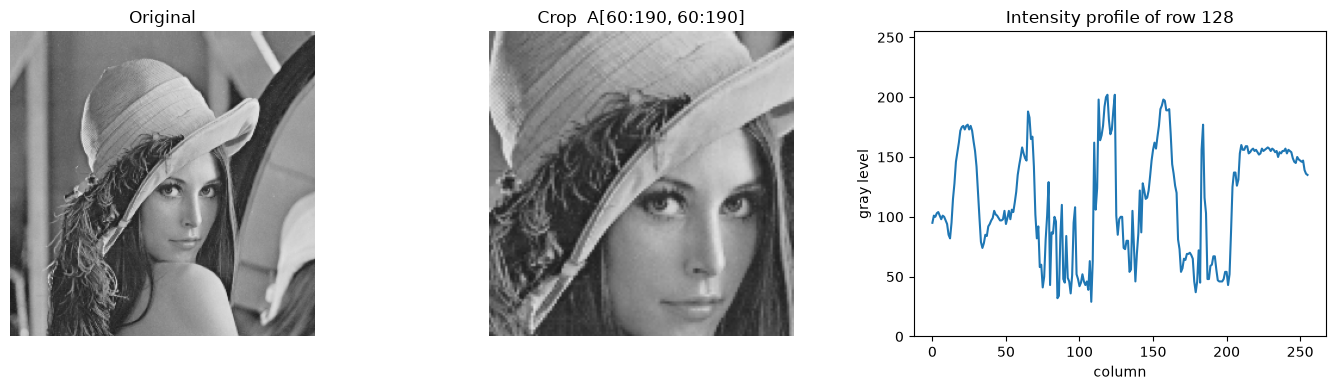

In [25]:
# ---- 2. Indexing / slicing: cropping a region of interest ----------------------
print("--- 2. Slicing ----------------------------------")
crop = A[60:190, 60:190]      # centre region
row  = A[128, :]              # one horizontal scan line
col  = A[:, 128]              # one vertical scan line
print("crop shape :", crop.shape, "| row shape :", row.shape, "| col shape :", col.shape)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(A, cmap='gray', vmin=0, vmax=255);    ax[0].set_title('Original');  ax[0].axis('off')
ax[1].imshow(crop, cmap='gray', vmin=0, vmax=255); ax[1].set_title('Crop  A[60:190, 60:190]'); ax[1].axis('off')
ax[2].plot(row); ax[2].set_title('Intensity profile of row 128')
ax[2].set_xlabel('column'); ax[2].set_ylabel('gray level'); ax[2].set_ylim(0, 255)
plt.tight_layout(); plt.show()

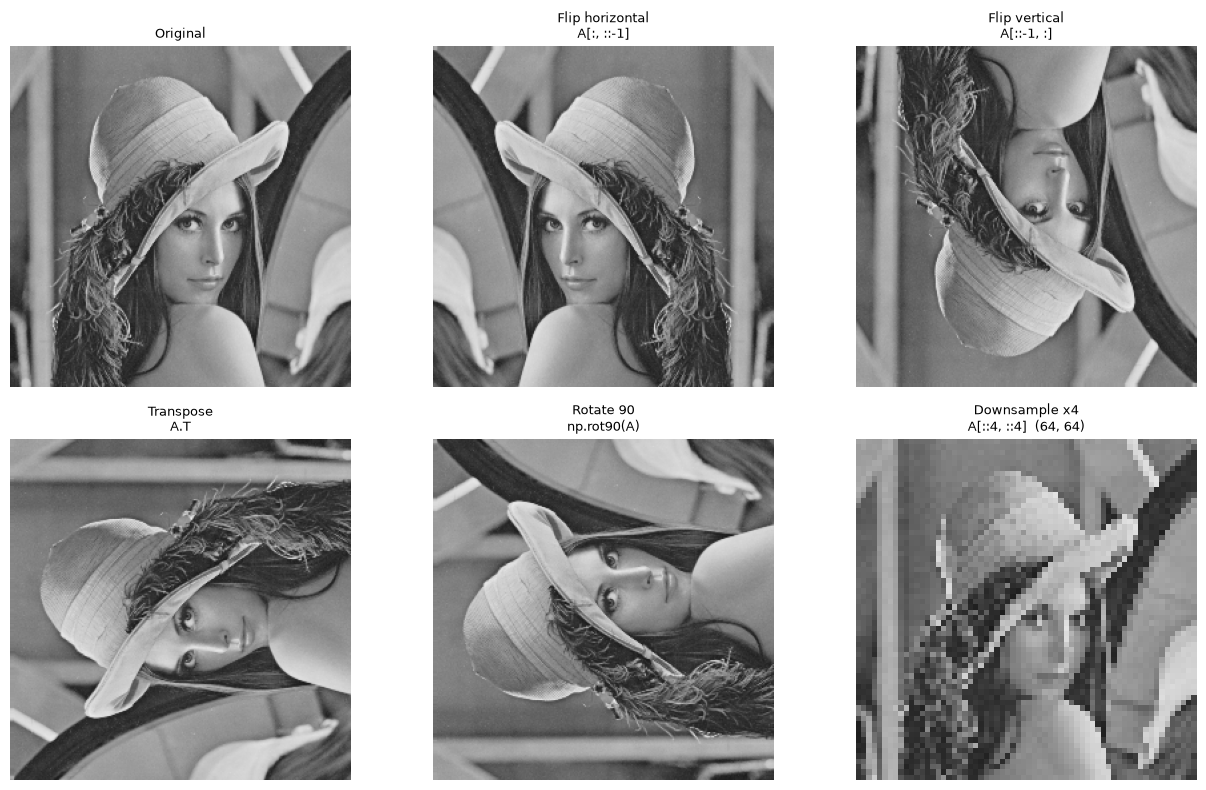

In [26]:
# ---- 3. Geometric operations with pure NumPy -----------------------------------
flip_h     = A[:, ::-1]        # mirror left-right
flip_v     = A[::-1, :]        # mirror up-down
transpose  = A.T               # transpose
rot90      = np.rot90(A)       # rotate by 90 degrees
downsample = A[::4, ::4]       # keep 1 pixel out of 4 -> sampling (Lab 2!)

titles = ['Original', 'Flip horizontal\nA[:, ::-1]', 'Flip vertical\nA[::-1, :]',
          'Transpose\nA.T', 'Rotate 90\nnp.rot90(A)', f'Downsample x4\nA[::4, ::4]  {downsample.shape}']
imgs = [A, flip_h, flip_v, transpose, rot90, downsample]

plt.figure(figsize=(13, 8))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 3, i); plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9); plt.axis('off')
plt.tight_layout(); plt.show()

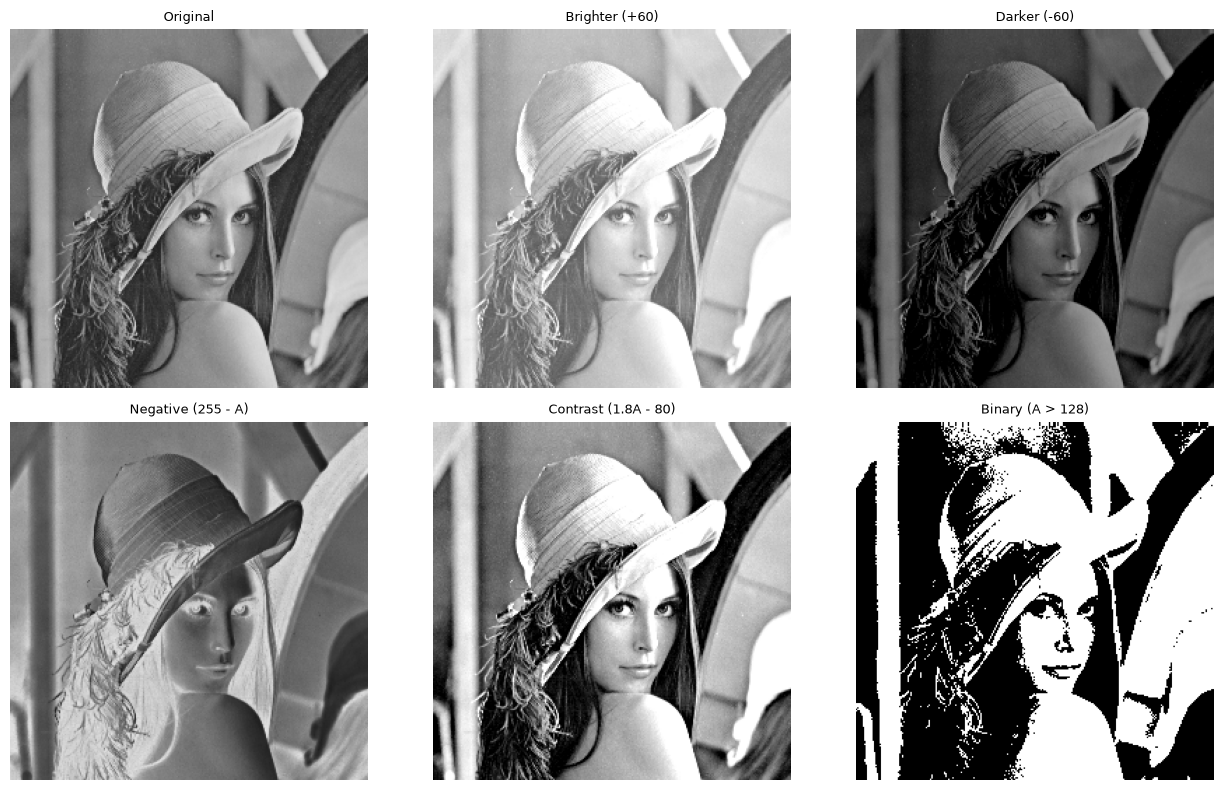

In [27]:
# ---- 4. Point (pixel-wise) operations ------------------------------------------
A16      = A.astype(np.int16)                                # avoid uint8 wrap-around
brighter = np.clip(A16 + 60, 0, 255).astype(np.uint8)        # add a constant
darker   = np.clip(A16 - 60, 0, 255).astype(np.uint8)        # subtract a constant
negative = (255 - A).astype(np.uint8)                        # photographic negative
contrast = np.clip(1.8 * A16 - 80, 0, 255).astype(np.uint8)  # linear stretching
binary   = np.where(A > 128, 255, 0).astype(np.uint8)        # thresholding

titles = ['Original', 'Brighter (+60)', 'Darker (-60)',
          'Negative (255 - A)', 'Contrast (1.8A - 80)', 'Binary (A > 128)']
imgs = [A, brighter, darker, negative, contrast, binary]

plt.figure(figsize=(13, 8))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 3, i); plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9); plt.axis('off')
plt.tight_layout(); plt.show()

--- 5. Boolean masking --------------------------
mask dtype / shape      : bool (256, 256)
bright pixels (A > 150) : 20681 (31.6 % of the image)
their mean value        : 177.42


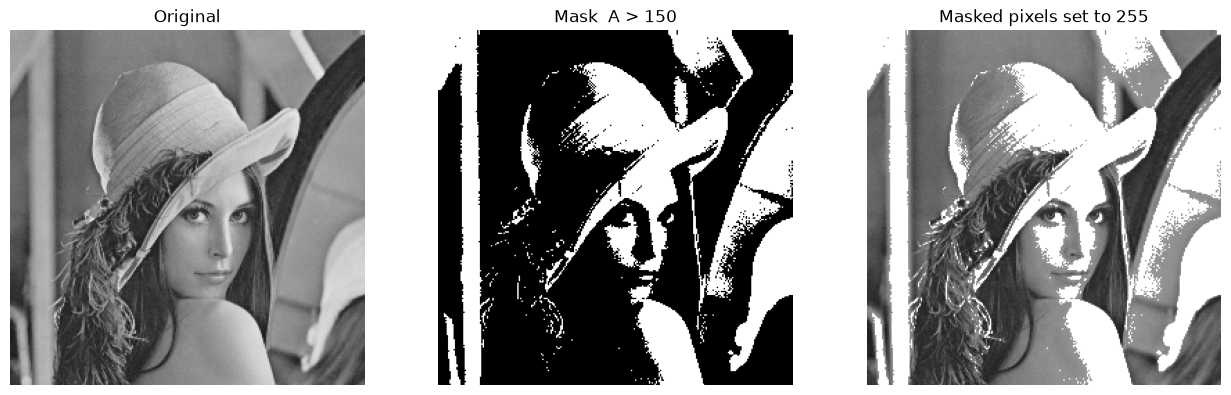

In [28]:
# ---- 5. Boolean masking: work only on the pixels that satisfy a condition -------
mask = A > 150                                 # a boolean array of the same shape as A
print("--- 5. Boolean masking --------------------------")
print("mask dtype / shape      :", mask.dtype, mask.shape)
print("bright pixels (A > 150) :", mask.sum(), f"({100 * mask.mean():.1f} % of the image)")
print("their mean value        :", A[mask].mean().round(2))

highlighted = A.copy()
highlighted[mask] = 255                        # force the bright pixels to white

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(A, cmap='gray', vmin=0, vmax=255);           ax[0].set_title('Original'); ax[0].axis('off')
ax[1].imshow(mask, cmap='gray');                          ax[1].set_title('Mask  A > 150'); ax[1].axis('off')
ax[2].imshow(highlighted, cmap='gray', vmin=0, vmax=255); ax[2].set_title('Masked pixels set to 255'); ax[2].axis('off')
plt.tight_layout(); plt.show()

--- 6. Reshaping / stacking ---------------------
flatten           : (65536,) -> [162 162 162 163 165 162 155 160] ...
reshape(128, 512) : (128, 512)
hstack            : (256, 512)
vstack            : (512, 256)


dstack -> colour  : (256, 256, 3)


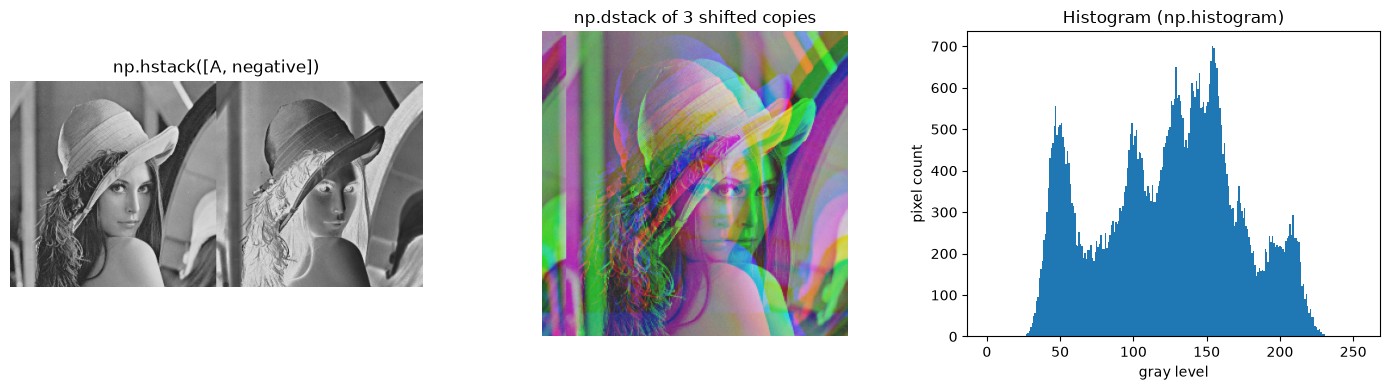

In [29]:
# ---- 6. Reshaping, stacking and the histogram ----------------------------------
print("--- 6. Reshaping / stacking ---------------------")
flat = A.flatten()
print("flatten           :", flat.shape, "->", flat[:8], "...")
print("reshape(128, 512) :", A.reshape(128, 512).shape)
print("hstack            :", np.hstack([A, negative]).shape)
print("vstack            :", np.vstack([A, negative]).shape)

# A 3-channel colour image can be built by stacking three 2-D arrays:
rgb = np.dstack([A, np.roll(A, 20, axis=1), np.roll(A, -20, axis=0)])
print("dstack -> colour  :", rgb.shape)

# The histogram is just a count of the values of the flattened array:
hist, bins = np.histogram(flat, bins=256, range=(0, 256))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(np.hstack([A, negative]), cmap='gray', vmin=0, vmax=255)
ax[0].set_title('np.hstack([A, negative])'); ax[0].axis('off')
ax[1].imshow(rgb); ax[1].set_title('np.dstack of 3 shifted copies'); ax[1].axis('off')
ax[2].bar(bins[:-1], hist, width=1.0)
ax[2].set_title('Histogram (np.histogram)')
ax[2].set_xlabel('gray level'); ax[2].set_ylabel('pixel count')
plt.tight_layout(); plt.show()

--- 7. Two-image arithmetic ---------------------
A : (256, 256) uint8  | B : (256, 256) uint8


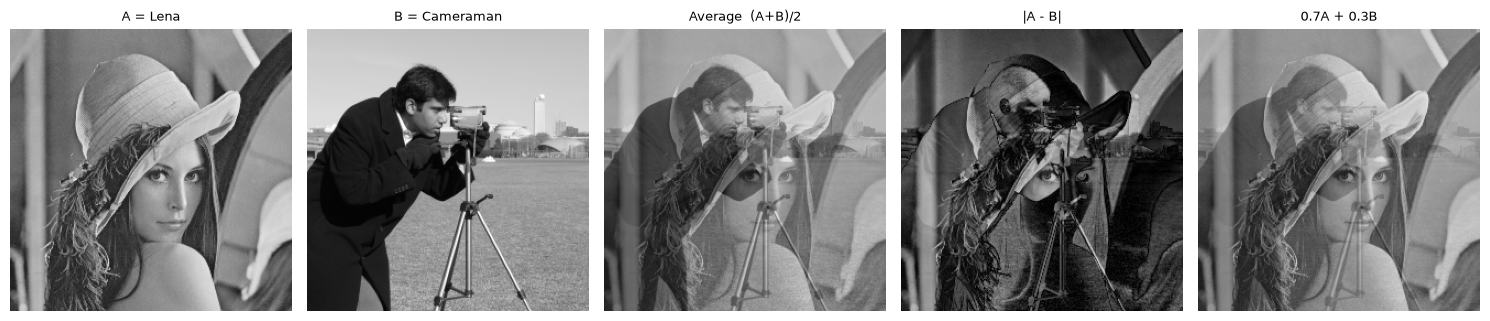

In [30]:
# ---- 7. Operations between two arrays (preview of Lab 2) -----------------------
B = np.array(Image.open('../images/cameraman.tif'))
print("--- 7. Two-image arithmetic ---------------------")
print("A :", A.shape, A.dtype, " | B :", B.shape, B.dtype)

average    = ((A.astype(np.int16) + B.astype(np.int16)) // 2).astype(np.uint8)
difference = np.abs(A.astype(np.int16) - B.astype(np.int16)).astype(np.uint8)
blend      = np.clip(0.7 * A + 0.3 * B, 0, 255).astype(np.uint8)

titles = ['A = Lena', 'B = Cameraman', 'Average  (A+B)/2', '|A - B|', '0.7A + 0.3B']
imgs = [A, B, average, difference, blend]
plt.figure(figsize=(15, 3.4))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 5, i); plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9); plt.axis('off')
plt.tight_layout(); plt.show()

<a id="conclusion"></a>
## 7. Conclusion

* The working environment (Anaconda, Jupyter / Spyder) was installed together with **NumPy, OpenCV, Pillow, Matplotlib, SciPy and scikit-image**, and all versions were verified in code.
* Both cheat sheets were exercised: data types, strings, lists, tuples, dictionaries, sets, conditions, loops, comprehensions and functions; then array creation, attributes, indexing, slicing, broadcasting, statistics and reshaping.
* Images were **loaded** with OpenCV (`cv2.imread` → NumPy array, **BGR** by default) and with PIL (`Image.open` → `Image` object, size reported as **(W, H)**), and displayed with Matplotlib.
* Images were **stored** with `cv2.imwrite()` and `Image.save()`; the encoder is chosen from the file extension, and JPEG was measured to be lossy (the pixel values change after a save / load round-trip) while PNG, BMP and TIFF are lossless.
* Finally the image was manipulated **as a pure NumPy array**: cropping, flipping, transposing, down-sampling, point operations (brightness, negative, contrast, thresholding), boolean masking, stacking, histogram computation and two-image arithmetic.

**Main conclusion (Outcome #1).** A digital image is represented in a computer as a 2-D array of integers for a gray-scale image (`H × W`, `uint8`, values 0–255), or as a 3-D array for a colour image (`H × W × 3`). Because it is only an array, *manipulating* an image means doing arithmetic and indexing on numbers — which is exactly what NumPy does. The pitfall to remember is the **`uint8` range**: results outside 0–255 wrap around, unless the computation is done in a wider type and then clipped, or a saturating function such as `cv2.add()` is used.